<a href="https://colab.research.google.com/github/zohaibahmedshaikh32-coder/Machine_Learning_labs/blob/main/MlLab08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

In [ ]:
# Task 1: Load the dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

print(f"Dataset Shape: {df.shape}")
print("First 5 rows of the dataset:")
print(df.head())

Dataset Shape: (569, 31)
First 5 rows of the dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst 

In [ ]:
# Task 2: Data Preprocessing
# 1. Simulate missing values and categorical data for demonstration purposes
df.loc[0:5, 'mean radius'] = np.nan  # Introduce some missing values
df['diagnosis_cat'] = pd.Series(['M' if x == 0 else 'B' for x in df['target']]) # Categorical column

# 2. Handle Missing Values using SimpleImputer
imputer = SimpleImputer(strategy='mean')
df['mean radius'] = imputer.fit_transform(df[['mean radius']])

# 3. Encode Categorical Data
label_encoder = LabelEncoder()
df['encoded_diagnosis'] = label_encoder.fit_transform(df['diagnosis_cat'])

# Drop extra columns used for demo encoding/labeling
X = df.drop(columns=['target', 'diagnosis_cat', 'encoded_diagnosis'])
y = df['target']

# 4. Feature Scaling (Crucial for KNN distance metrics)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Preprocessing complete. Missing values handled, categorical data encoded, and features scaled.")

Preprocessing complete. Missing values handled, categorical data encoded, and features scaled.


In [ ]:
# Task 3: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 455 samples
Testing set size: 114 samples


In [ ]:
# Task 4: Train KNN classifiers with K = 3, 5, and 7
k_values = [3, 5, 7]
trained_models = {}

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    trained_models[k] = knn
    print(f"Trained KNN model with K = {k}")

Trained KNN model with K = 3
Trained KNN model with K = 5
Trained KNN model with K = 7


In [ ]:
# Task 5: Make predictions on the test set
predictions = {}

for k, model in trained_models.items():
    preds = model.predict(X_test)
    predictions[k] = preds
    print(f"Predictions for K = {k} (First 10): {preds[:10]}")

Predictions for K = 3 (First 10): [0 1 0 1 0 1 1 0 0 0]
Predictions for K = 5 (First 10): [0 1 0 0 0 1 1 0 0 0]
Predictions for K = 7 (First 10): [0 1 0 1 0 1 1 0 0 0]


In [ ]:
# Task 6: Evaluate performance metrics
evaluation_results = []

for k in k_values:
    preds = predictions[k]
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted')
    rec = recall_score(y_test, preds, average='weighted')
    f1 = f1_score(y_test, preds, average='weighted')

    evaluation_results.append({
        'K Value': k,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

results_df = pd.DataFrame(evaluation_results)
print("\nModel Performance Evaluation:")
print(results_df.to_string(index=False))


Model Performance Evaluation:
 K Value  Accuracy  Precision  Recall  F1-Score
       3    0.9825     0.9829  0.9825    0.9824
       5    0.9649     0.9652  0.9649    0.9647
       7    0.9649     0.9652  0.9649    0.9647


K =  1 -> Accuracy: 0.9386
K =  2 -> Accuracy: 0.9298
K =  3 -> Accuracy: 0.9825
K =  4 -> Accuracy: 0.9386
K =  5 -> Accuracy: 0.9649
K =  6 -> Accuracy: 0.9474
K =  7 -> Accuracy: 0.9649
K =  8 -> Accuracy: 0.9737
K =  9 -> Accuracy: 0.9737
K = 10 -> Accuracy: 0.9737
K = 11 -> Accuracy: 0.9737
K = 12 -> Accuracy: 0.9737
K = 13 -> Accuracy: 0.9737
K = 14 -> Accuracy: 0.9649
K = 15 -> Accuracy: 0.9649
K = 16 -> Accuracy: 0.9737
K = 17 -> Accuracy: 0.9825
K = 18 -> Accuracy: 0.9825
K = 19 -> Accuracy: 0.9737
K = 20 -> Accuracy: 0.9649


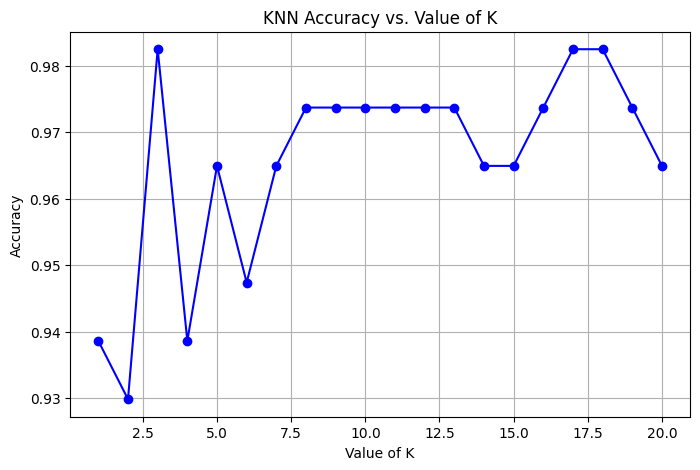

In [ ]:
# Task 7: Test accuracy changes across a range of K values
k_range = range(1, 21)
accuracies = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    preds = knn.predict(X_test)
    accuracies.append(accuracy_score(y_test, preds))

# Display the accuracy for each K
for k, acc in zip(k_range, accuracies):
    print(f"K = {2:2d} -> Accuracy: {acc:.4f}" if False else f"K = {k:2d} -> Accuracy: {acc:.4f}")

# Optional: Plotting accuracy vs K
plt.figure(figsize=(8, 5))
plt.plot(k_range, accuracies, marker='o', linestyle='-', color='b')
plt.title('KNN Accuracy vs. Value of K')
plt.xlabel('Value of K')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()